# Part B – Handling Outliers
**Project:** Data Cleanser – Practical-2 (Data Preprocessing & Feature Engineering)  
**Domain:** Healthcare – patient health records → predicting *heart-disease risk*  
**Focus:** Outlier detection / treatment: Z-score, IQR, Percentile, Winsorization

---

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# ---- paths (notebooks are run from the /Notebooks folder) ----
RAW   = "../Data/Raw/patient_health_records_raw.csv"
TRUTH = "../Data/External/ground_truth_clean_values.csv"   # clean values before corruption (evaluation only)
PROC  = "../Data/Processed/"
VIZ   = "../Visualization/"

SEED  = 42
NUM   = ["age", "bmi", "cholesterol", "glucose"]           # numeric columns that contain missing values
CAT   = ["gender", "region"]                               # categorical columns that contain missing values
OUTCOLS = ["bmi", "blood_pressure", "cholesterol", "glucose"]  # columns that contain outliers
print("Setup complete ✔")

Setup complete ✔

## Part B – Handling Outliers
**Tasks covered:** (3) detect & remove outliers with Z-score, IQR and Percentile methods, (4) Winsorization, (5) before-vs-after comparison.

### B.1 Load the imputed dataset from Part A
We continue from `imputed_best.csv` (all missing values already filled by the best technique of Part A).

In [2]:
from scipy import stats
from scipy.stats import mstats
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

df    = pd.read_csv(PROC + "imputed_best.csv")
raw   = pd.read_csv(RAW)
truth = pd.read_csv(TRUTH)
print("Dataset shape:", df.shape, "| missing cells:", int(df.isna().sum().sum()))
df[OUTCOLS].describe().T.round(2).assign(skew=df[OUTCOLS].skew().round(2))

Dataset shape: (500, 9) | missing cells: 0

,count,mean,std,min,25%,50%,75%,max,skew
bmi,500.0,26.17,6.23,8.7,23.00,26.00,28.52,70.7,2.93
blood_pressure,500.0,126.08,20.08,94.4,117.40,123.45,130.22,265.4,4.20
cholesterol,500.0,201.06,54.17,50.0,177.08,197.50,219.18,618.3,3.85
glucose,500.0,99.03,51.06,65.0,84.28,92.10,99.30,499.0,6.09


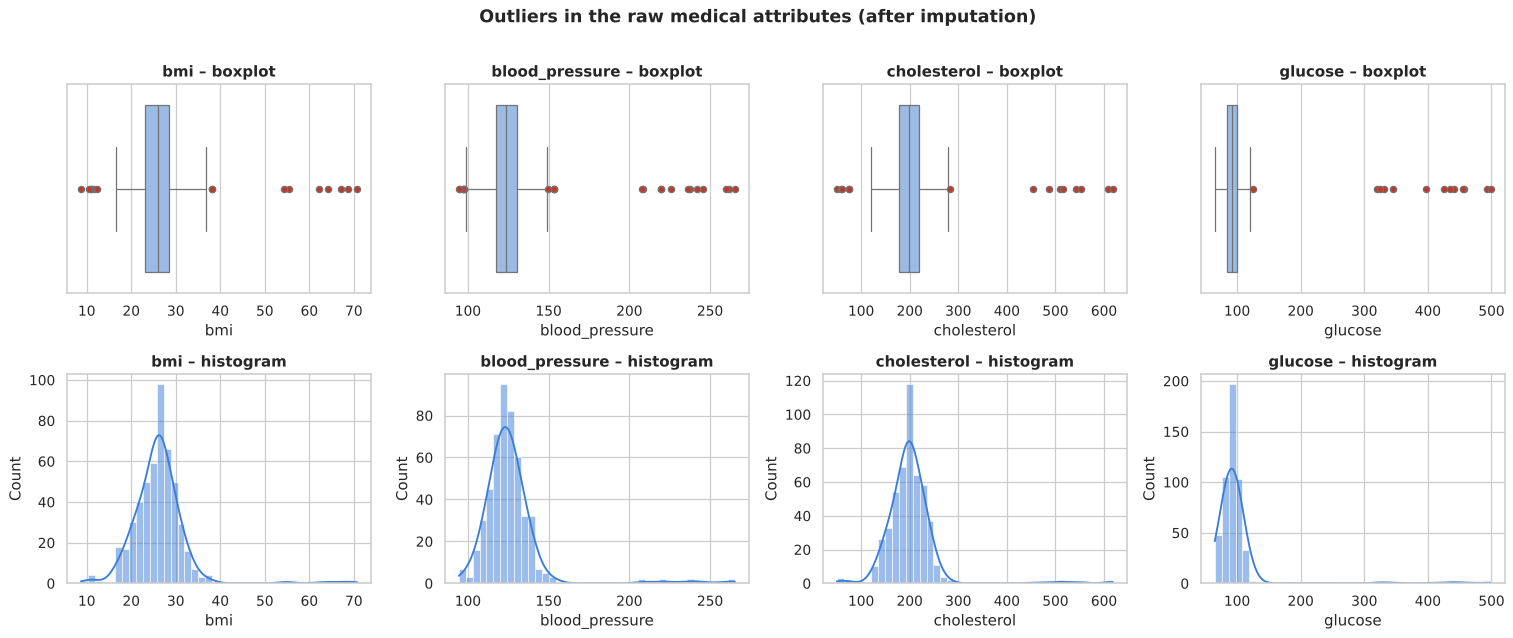

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for j, c in enumerate(OUTCOLS):
    sns.boxplot(x=df[c], ax=axes[0, j], color="#8fb8f0", flierprops=dict(marker="o", markerfacecolor="#c0392b", markersize=5))
    axes[0, j].set_title(f"{c} – boxplot")
    sns.histplot(df[c], kde=True, ax=axes[1, j], color="#3b7dd8", bins=40)
    axes[1, j].set_title(f"{c} – histogram")
plt.suptitle("Outliers in the raw medical attributes (after imputation)", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.savefig(VIZ + "05_outliers_before_treatment.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation – outliers before treatment**
The boxplots show long right tails and (for BMI and cholesterol) a few extreme low values. Roughly 12–13 values per column are physiologically implausible: BMI 8.7 – 70.7, systolic blood pressure up to 265 mmHg, cholesterol 50 – 618 mg/dL and glucose up to 499 mg/dL. The average absolute skewness of the four columns is about **4.3** (a normal distribution has 0), which would hurt any model that assumes roughly symmetric inputs.

### B.2 Reusable detection helpers

In [4]:
def z_flags(s, thr=3.0):
    """Classic Z-score rule: |(x - mean) / std| > thr"""
    return ((s - s.mean()) / s.std()).abs() > thr

def iqr_bounds(s, k=1.5):
    """Tukey fences: [Q1 - k*IQR , Q3 + k*IQR]"""
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return q1 - k * i, q3 + k * i

def iqr_flags(s, k=1.5):
    lo, hi = iqr_bounds(s, k)
    return (s < lo) | (s > hi)

def modz_flags(s, thr=3.5):
    """Robust 'modified Z-score' (median / MAD based) - bonus method"""
    mad = (s - s.median()).abs().median()
    return (0.6745 * (s - s.median()) / mad).abs() > thr
print("helpers ready")

helpers ready

### B.3 Z-score method – extreme `cholesterol` and `glucose` values (*Task 3a*)

In [5]:
z_rows = []
for c in ["cholesterol", "glucose"]:
    f = z_flags(df[c])
    z = (df[c] - df[c].mean()) / df[c].std()
    z_rows.append({"column": c, "mean": df[c].mean(), "std": df[c].std(), "outliers (|z|>3)": int(f.sum()),
                   "too high": int((z > 3).sum()), "too low": int((z < -3).sum()),
                   "min flagged": df.loc[f, c].min() if f.any() else np.nan, "max flagged": df.loc[f, c].max() if f.any() else np.nan})
pd.DataFrame(z_rows).round(2).set_index("column")

,mean,std,outliers (|z|>3),too high,too low,min flagged,max flagged
column,,,,,,,
cholesterol,201.06,54.17,8,8,0,453.9,618.3
glucose,99.03,51.06,12,12,0,320.6,499.0


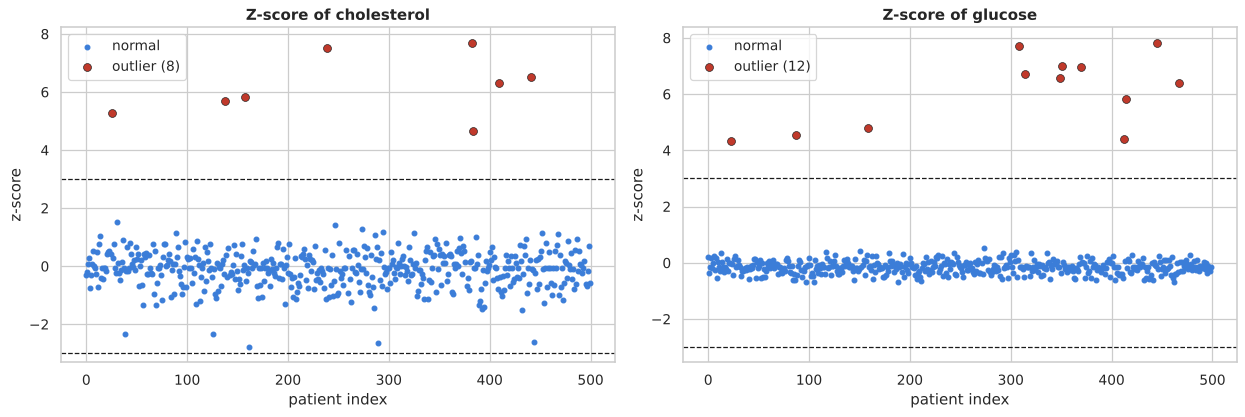

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, c in zip(axes, ["cholesterol", "glucose"]):
    z = (df[c] - df[c].mean()) / df[c].std()
    flag = z.abs() > 3
    ax.scatter(df.index[~flag], z[~flag], s=14, color="#3b7dd8", label="normal")
    ax.scatter(df.index[flag], z[flag], s=40, color="#c0392b", label=f"outlier ({flag.sum()})", edgecolor="k", lw=0.5)
    ax.axhline(3, color="k", ls="--", lw=1); ax.axhline(-3, color="k", ls="--", lw=1)
    ax.set_title(f"Z-score of {c}"); ax.set_xlabel("patient index"); ax.set_ylabel("z-score"); ax.legend()
plt.tight_layout(); plt.savefig(VIZ + "06_zscore_cholesterol_glucose.png", dpi=150)
plt.show()

In [7]:
# remove patients whose cholesterol OR glucose is an extreme Z-score outlier
z_mask = z_flags(df["cholesterol"]) | z_flags(df["glucose"])
df_z = df.loc[~z_mask].copy()
print(f"Rows before: {len(df)} | removed: {int(z_mask.sum())} | rows after: {len(df_z)}")
df_z.to_csv(PROC + "outliers_removed_zscore.csv", index=False)

Rows before: 500 | removed: 20 | rows after: 480

**Interpretation – Z-score**
* Z-score flagged **8 cholesterol** values (all too high) and **12 glucose** values (all too high); removing these patients drops **20 rows (4 %)**.
* **Weakness (masking effect):** the outliers themselves inflate the standard deviation (cholesterol std 54 vs about 32 for the uncorrupted data), so the threshold of ±3 sits far away. The extremely *low* cholesterol values (45–85 mg/dL) were never flagged because they would need z < −3. The rule also assumes a roughly normal distribution.

### B.4 IQR method – unusual `bmi` values (*Task 3b*)

In [8]:
lo, hi = iqr_bounds(df["bmi"])
q1, q3 = df["bmi"].quantile([0.25, 0.75])
iqr_mask = iqr_flags(df["bmi"])
print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | IQR = {q3 - q1:.2f}")
print(f"Lower fence = {lo:.2f} | Upper fence = {hi:.2f}")
print(f"BMI outliers: {int(iqr_mask.sum())}  (too low: {int((df['bmi'] < lo).sum())}, too high: {int((df['bmi'] > hi).sum())})")
df.loc[iqr_mask, ["patient_id", "age", "bmi", "disease_risk"]].sort_values("bmi").head(20)

Q1 = 23.00 | Q3 = 28.52 | IQR = 5.52
Lower fence = 14.71 | Upper fence = 36.81
BMI outliers: 15  (too low: 6, too high: 9)

,patient_id,age,bmi,disease_risk
11,PT0012,64.0,8.7,0
483,PT0484,61.0,10.5,0
317,PT0318,52.0,10.9,0
338,PT0339,69.0,11.0,1
281,PT0282,26.0,11.6,0
428,PT0429,31.0,12.2,0
288,PT0289,48.0,38.1,1
135,PT0136,37.0,38.1,1
409,PT0410,33.0,54.3,1
115,PT0116,44.0,55.4,0


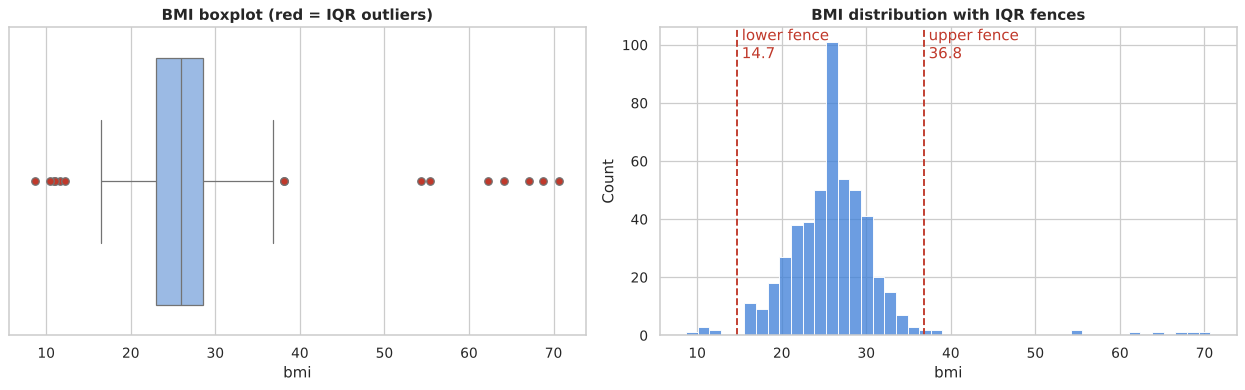

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(x=df["bmi"], ax=axes[0], color="#8fb8f0", flierprops=dict(markerfacecolor="#c0392b"))
axes[0].set_title("BMI boxplot (red = IQR outliers)")
sns.histplot(df["bmi"], bins=45, ax=axes[1], color="#3b7dd8")
for v, l in [(lo, "lower fence"), (hi, "upper fence")]:
    axes[1].axvline(v, color="#c0392b", ls="--"); axes[1].text(v, axes[1].get_ylim()[1] * 0.9, f" {l}\n {v:.1f}", color="#c0392b")
axes[1].set_title("BMI distribution with IQR fences")
plt.tight_layout(); plt.savefig(VIZ + "07_iqr_bmi_outliers.png", dpi=150)
plt.show()

In [10]:
df_iqr = df.loc[~iqr_mask].copy()
print(f"Rows before: {len(df)} | removed: {int(iqr_mask.sum())} | rows after: {len(df_iqr)}")
df_iqr.to_csv(PROC + "outliers_removed_iqr.csv", index=False)

Rows before: 500 | removed: 15 | rows after: 485

**Interpretation – IQR**
* Q1 = 23.00, Q3 = 28.52 → IQR = 5.52, fences **14.71 – 36.81**. **15 BMI values** are flagged (6 too low, 9 too high) vs only 7 found by the Z-score rule.
* 13 of the 15 are real corrupted values; two patients with BMI 38.1 are genuine (obese) measurements – a **false positive** of the rule. The IQR method is distribution-free and robust (quartiles are not moved by outliers) but can be strict on skewed columns.

### B.5 Percentile method – cap below the 1st and above the 99th percentile (*Task 3c*)

In [11]:
df_pct = df.copy()
rows = []
for c in OUTCOLS:
    p1, p99 = df[c].quantile([0.01, 0.99])
    n_lo, n_hi = int((df[c] < p1).sum()), int((df[c] > p99).sum())
    df_pct[c] = df[c].clip(p1, p99)
    rows.append({"column": c, "1st pct": p1, "99th pct": p99, "capped low": n_lo, "capped high": n_hi,
                 "min after": df_pct[c].min(), "max after": df_pct[c].max()})
df_pct.to_csv(PROC + "outliers_capped_percentile.csv", index=False)
pd.DataFrame(rows).set_index("column").round(2)

,1st pct,99th pct,capped low,capped high,min after,max after
column,,,,,,
bmi,12.19,55.47,5,5,12.19,55.47
blood_pressure,97.70,237.54,5,5,97.70,237.54
cholesterol,119.55,508.98,5,5,119.55,508.98
glucose,66.99,434.57,5,5,66.99,434.57


### B.6 Winsorization – cap extreme values instead of removing them (*Task 4*)
`scipy.stats.mstats.winsorize(limits=(0.05, 0.05))` replaces the lowest 5 % of values with the 5th-percentile value and the highest 5 % with the 95th-percentile value (symmetric, more aggressive than the 1 %/99 % percentile cap).

In [12]:
WIN = 0.05
df_win = df.copy()
rows = []
for c in OUTCOLS:
    w = np.asarray(mstats.winsorize(df[c].values, limits=(WIN, WIN)))
    rows.append({"column": c, "values changed": int((w != df[c].values).sum()),
                 "min before": df[c].min(), "min after": w.min(), "max before": df[c].max(), "max after": w.max()})
    df_win[c] = w
df_win.to_csv(PROC + "outliers_winsorized.csv", index=False)
pd.DataFrame(rows).set_index("column").round(2)

,values changed,min before,min after,max before,max after
column,,,,,
bmi,50,8.7,18.2,70.7,32.9
blood_pressure,49,94.4,107.1,265.4,141.8
cholesterol,50,50.0,141.6,618.3,248.1
glucose,50,65.0,71.7,499.0,113.3


**Interpretation – percentile cap vs winsorization**
* **Percentile (1 % / 99 %)** only touches 5 values per tail per column. Because about 2.5 % of each column is corrupted, the 99th percentile *is itself an outlier* (glucose cap = 434.6, cholesterol cap = 509.0, blood-pressure cap = 237.5). The values are capped to another extreme value, so the problem stays – 50 corrupted cells are still outside the true range afterwards (see B.9).
* **Winsorization (5 % each side)** pulls glucose max from 499 → 113.3, cholesterol 618 → 248.1, blood pressure 265 → 141.8 and BMI 70.7 → 32.9 (and BMI min 8.7 → 18.2). All extremes are gone and no row is lost, but ≈ 50 values per column (10 %) are modified, including some legitimate ones.

### B.7 Which method flags what? (all four columns, all detection rules)

In [13]:
det = pd.DataFrame({
    "Z-score (|z|>3)":       {c: int(z_flags(df[c]).sum()) for c in OUTCOLS},
    "Modified Z (MAD>3.5)":  {c: int(modz_flags(df[c]).sum()) for c in OUTCOLS},
    "IQR (1.5 x IQR)":       {c: int(iqr_flags(df[c]).sum()) for c in OUTCOLS},
    "Percentile (<1% or >99%)": {c: int(((df[c] < df[c].quantile(.01)) | (df[c] > df[c].quantile(.99))).sum()) for c in OUTCOLS},
    "Winsorize 5% (values changed)": {c: int(((df[c] < df[c].quantile(.05)) | (df[c] > df[c].quantile(.95))).sum()) for c in OUTCOLS},
})
# ground truth: how many cells were *really* corrupted?  (value differs from the true, pre-corruption value)
det["TRUE injected outliers"] = {c: int((raw[c].notna() & (raw[c].round(1) != truth[c].round(1))).sum()) for c in OUTCOLS}
det

,Z-score (|z|>3),Modified Z (MAD>3.5),IQR (1.5 x IQR),Percentile (<1% or >99%),Winsorize 5% (values changed),TRUE injected outliers
bmi,7,12,15,10,50,13
blood_pressure,12,12,22,10,49,12
cholesterol,8,13,14,10,50,13
glucose,12,12,13,10,50,12


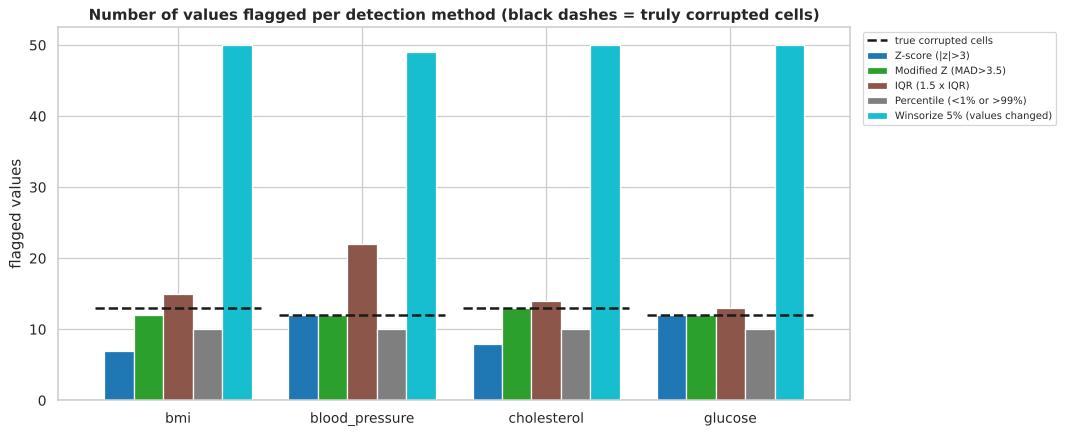

In [14]:
ax = det.drop(columns="TRUE injected outliers").plot(kind="bar", figsize=(12, 5), width=0.8, colormap="tab10")
for i, c in enumerate(OUTCOLS):
    ax.hlines(det.loc[c, "TRUE injected outliers"], i - 0.45, i + 0.45, color="k", ls="--", lw=2,
              label="true corrupted cells" if i == 0 else None)
ax.set_title("Number of values flagged per detection method (black dashes = truly corrupted cells)")
ax.set_ylabel("flagged values"); ax.set_xlabel(""); plt.xticks(rotation=0); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.savefig(VIZ + "08_outlier_detection_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation – detection rules compared with the true number of corrupted cells**
* The robust **modified Z-score (MAD)** is the most accurate detector here (12, 12, 13, 12 flags vs 13, 12, 13, 12 truly corrupted cells).
* **IQR** is close but slightly over-flags (e.g. 22 blood-pressure values vs 12 true) because genuinely high but legitimate patients fall outside the fences.
* **Classic Z-score** under-detects BMI (7 of 13) and cholesterol (8 of 13) because the outliers inflate the standard deviation.
* **Percentile** and **Winsorization** flag a *fixed share* of the data (≈ 2 % and 10 %) regardless of how many outliers really exist – they are treatments, not detectors.

### B.8 Dataset shape & summary – before vs after outlier treatment (*Task 5*)
For a **fair comparison** every treatment is now applied to *all four* columns that contain outliers.

In [15]:
def t_none(d, cols):            return d.copy()
def t_z_remove(d, cols):        return d.loc[~np.any([z_flags(d[c]) for c in cols], axis=0)].copy()
def t_iqr_remove(d, cols):      return d.loc[~np.any([iqr_flags(d[c]) for c in cols], axis=0)].copy()
def t_pct_cap(d, cols):
    o = d.copy()
    for c in cols: o[c] = d[c].clip(*d[c].quantile([0.01, 0.99]))
    return o
def t_winsor(d, cols, lim=WIN):
    o = d.copy()
    for c in cols: o[c] = np.asarray(mstats.winsorize(d[c].values, limits=(lim, lim)))
    return o
def t_iqr_cap(d, cols):
    o = d.copy()
    for c in cols: o[c] = d[c].clip(*iqr_bounds(d[c]))
    return o

TREATMENTS = {
    "No treatment": t_none,
    "Z-score removal (|z|>3)": t_z_remove,
    "IQR removal (1.5xIQR)": t_iqr_remove,
    "Percentile cap (1%-99%)": t_pct_cap,
    "Winsorization (5%)": t_winsor,
    "IQR capping (1.5xIQR)": t_iqr_cap,
}
treated = {n: f(df, OUTCOLS) for n, f in TREATMENTS.items()}

shape_tbl = pd.DataFrame({"rows": {n: d.shape[0] for n, d in treated.items()},
                          "columns": {n: d.shape[1] for n, d in treated.items()}})
shape_tbl["rows lost"] = df.shape[0] - shape_tbl["rows"]
shape_tbl["data loss %"] = (shape_tbl["rows lost"] / df.shape[0] * 100).round(1)
shape_tbl

,rows,columns,rows lost,data loss %
No treatment,500,9,0,0.0
Z-score removal (|z|>3),462,9,38,7.6
IQR removal (1.5xIQR),438,9,62,12.4
Percentile cap (1%-99%),500,9,0,0.0
Winsorization (5%),500,9,0,0.0
IQR capping (1.5xIQR),500,9,0,0.0


In [16]:
summ = pd.concat({n: d[OUTCOLS].agg(["mean", "std", "min", "max"]).T for n, d in treated.items()}, axis=0).round(2)
summ.index.names = ["treatment", "column"]
summ.unstack("treatment")["std"]       # compare the spread (std) of every column under each treatment

treatment,No treatment,Z-score removal (|z|>3),IQR removal (1.5xIQR),Percentile cap (1%-99%),Winsorization (5%),IQR capping (1.5xIQR)
column,,,,,,
bmi,6.23,4.41,3.98,5.52,3.95,4.38
blood_pressure,20.08,10.06,9.28,18.97,9.45,10.56
cholesterol,54.17,33.09,29.54,48.96,29.28,32.67
glucose,51.06,11.42,11.27,48.55,11.20,12.16


In [17]:
summ.unstack("treatment")["max"]

treatment,No treatment,Z-score removal (|z|>3),IQR removal (1.5xIQR),Percentile cap (1%-99%),Winsorization (5%),IQR capping (1.5xIQR)
column,,,,,,
bmi,70.7,38.1,36.8,55.47,32.9,36.81
blood_pressure,265.4,153.1,149.1,237.54,141.8,149.46
cholesterol,618.3,283.5,263.8,508.98,248.1,282.33
glucose,499.0,125.7,120.1,434.57,113.3,121.84


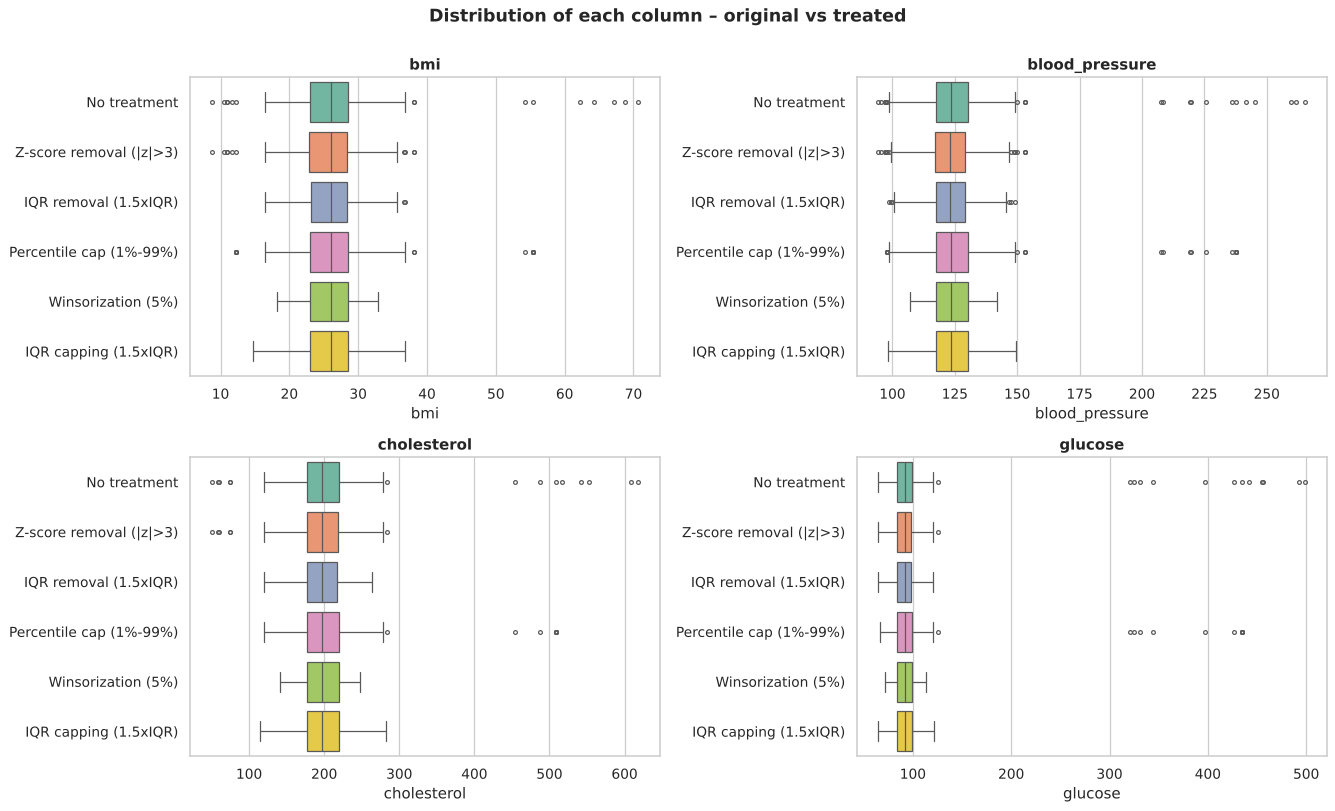

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
long = pd.concat([d[OUTCOLS].assign(treatment=n) for n, d in treated.items()])
for ax, c in zip(axes.ravel(), OUTCOLS):
    sns.boxplot(data=long, y="treatment", x=c, ax=ax, palette="Set2", flierprops=dict(markersize=3))
    ax.set_title(c); ax.set_ylabel("")
plt.suptitle("Distribution of each column – original vs treated", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout(); plt.savefig(VIZ + "09_before_after_outlier_treatment.png", dpi=150, bbox_inches="tight")
plt.show()

### B.9 Which treatment preserves data quality best?
We use four yardsticks, three of which are possible only because we know the true values:

1. **Rows retained** (no data loss).  
2. **Error vs truth** – average normalised RMSE between the treated values and the original, uncorrupted values on the rows that remain (lower = closer to reality).  
3. **Cells still outside the true physiological range** – corrupted values that survived the treatment.  
4. **Downstream usefulness** – 5-fold × 5-repeat cross-validated ROC-AUC of a logistic regression predicting `disease_risk`.

In [19]:
def cv_auc(d, repeats=5):
    X = d[["age", "bmi", "blood_pressure", "cholesterol", "glucose"]].astype(float).copy()
    X["male"] = (d["gender"] == "Male").astype(float)
    X = pd.concat([X, pd.get_dummies(d["region"], prefix="region").astype(float)], axis=1)
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=SEED)
    s = cross_val_score(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), X, d["disease_risk"], cv=cv, scoring="roc_auc")
    return s.mean(), s.std()

tr = truth.set_index("patient_id")
rows = []
for n, d in treated.items():
    t = tr.loc[d["patient_id"]]
    nrmse = np.mean([np.sqrt(((d[c].values - t[c].values) ** 2).mean()) / truth[c].std() for c in OUTCOLS])
    outside = int(sum(((d[c].values < truth[c].min() - 1e-9) | (d[c].values > truth[c].max() + 1e-9)).sum() for c in OUTCOLS))
    auc, auc_sd = cv_auc(d)
    rows.append({"treatment": n, "rows_kept": len(d), "data_loss_%": round((1 - len(d) / len(df)) * 100, 1),
                 "NRMSE_vs_truth": nrmse, "cells_outside_true_range": outside,
                 "avg_|skew|": d[OUTCOLS].skew().abs().mean(), "cv_AUC": auc, "cv_AUC_std": auc_sd})
outlier_eval = pd.DataFrame(rows).set_index("treatment")
outlier_eval.round(4).to_csv(PROC + "outlier_method_comparison.csv")
outlier_eval.round(4)

,rows_kept,data_loss_%,NRMSE_vs_truth,cells_outside_true_range,avg_|skew|,cv_AUC,cv_AUC_std
treatment,,,,,,,
No treatment,500,0.0,2.1282,50,4.2661,0.8332,0.0395
Z-score removal (|z|>3),462,7.6,0.3160,11,0.2878,0.8839,0.0350
IQR removal (1.5xIQR),438,12.4,0.2208,0,0.0765,0.8727,0.0270
Percentile cap (1%-99%),500,0.0,1.9401,50,3.7811,0.8392,0.0393
Winsorization (5%),500,0.0,0.4044,0,0.1053,0.8750,0.0365
IQR capping (1.5xIQR),500,0.0,0.4771,11,0.1025,0.8700,0.0374


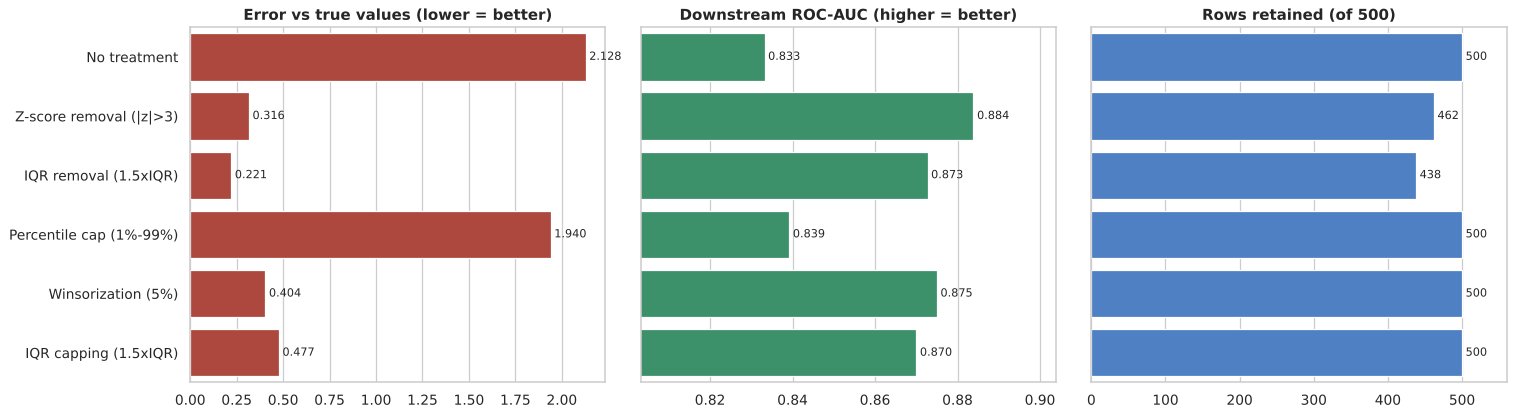

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
order = outlier_eval.index
for ax, (col, ttl, clr, fmt) in zip(axes, [("NRMSE_vs_truth", "Error vs true values (lower = better)", "#c0392b", "{:.3f}"),
                                           ("cv_AUC", "Downstream ROC-AUC (higher = better)", "#2e9e6b", "{:.3f}"),
                                           ("rows_kept", "Rows retained (of 500)", "#3b7dd8", "{:.0f}")]):
    sns.barplot(x=outlier_eval[col], y=order, color=clr, ax=ax)
    for i, v in enumerate(outlier_eval[col]):
        ax.text(v, i, " " + fmt.format(v), va="center", fontsize=9)
    ax.set_title(ttl); ax.set_ylabel(""); ax.set_xlabel("")
    if col == "cv_AUC": ax.set_xlim(outlier_eval[col].min() - 0.03, outlier_eval[col].max() + 0.02)
    if col == "rows_kept": ax.set_xlim(0, 560)
    if col != "NRMSE_vs_truth": ax.set_yticklabels([])
plt.tight_layout(); plt.savefig(VIZ + "10_outlier_method_evaluation.png", dpi=150)
plt.show()

**Interpretation – which treatment preserves data quality best?**
* **No treatment**: error vs truth 2.13, 50 cells beyond the true range, ROC-AUC 0.833.
* **Percentile cap 1 %/99 %**: practically useless here (error 1.94, still 50 extreme cells) because the cap value is itself an outlier.
* **Removal (Z-score / IQR)** gives the cleanest values (error 0.316 / 0.221) but **loses 7.6 % / 12.4 % of the patients**; IQR removal also removes legitimate extreme patients.
* **Winsorization 5 %** keeps all 500 rows, leaves **0** values outside the true range, error 0.404 and AUC 0.875.
* **IQR capping** keeps all rows too (error 0.477, 11 cells still slightly out of range, AUC 0.870).
* The AUC differences between the treatments (0.870 – 0.884) are smaller than the CV standard deviation (≈ 0.03), so they are statistically equivalent – the real gain is versus *no treatment* (0.833 → ≈ 0.875). Note that the removal methods are scored on fewer rows, so their AUC is not strictly comparable.

**Verdict:** *Winsorization (capping) preserves data quality best* – no data loss, no extreme values left, good downstream performance. Removal is only justified when an outlier is a certain measurement error and the data set is large.